# 02_Heterogeneous effects by user segment
Splits the within-user treatment effect from `01_treatment_effect` by user segment to find where exploration traffic is cheapest. Segments come from `user_features_pure.csv`: activity level (`user_active_degree`) and account age (`register_days_range`), each pooled into five groups. Requires the Parquet files created in `00_data_overview`.

## 1. Load data

### Register the `control`, `treatment` and `user_features` views
`control` and `treatment` read the Parquet files from `00`. `user_features` has one row per user and is small, so it is read directly from the raw CSV. Re-run this cell after a kernel restart.

In [10]:
import duckdb

duckdb.sql("SET enable_progress_bar = false")

duckdb.sql("""
CREATE OR REPLACE VIEW control       AS SELECT * FROM '../data/processed/control.parquet';
CREATE OR REPLACE VIEW treatment     AS SELECT * FROM '../data/processed/treatment.parquet';
CREATE OR REPLACE VIEW user_features AS SELECT * FROM read_csv_auto('../data/raw/KuaiRand-Pure/data/user_features_pure.csv');
""")

### Segment distribution
Number of users in each activity level and account-age range, across all users in the feature file.

In [11]:
duckdb.sql("""
SELECT user_active_degree, COUNT(*) AS n_users,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM user_features
GROUP BY user_active_degree
ORDER BY n_users DESC
""").show()

duckdb.sql("""
SELECT register_days_range, COUNT(*) AS n_users,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM user_features
GROUP BY register_days_range
ORDER BY TRY_CAST(regexp_extract(register_days_range, '^[0-9]+') AS INTEGER)   -- sort ranges by their lower bound
""").show()

┌────────────────────┬─────────┬────────┐
│ user_active_degree │ n_users │  pct   │
│      varchar       │  int64  │ double │
├────────────────────┼─────────┼────────┤
│ full_active        │   17959 │  65.82 │
│ high_active        │    6158 │  22.57 │
│ middle_active      │    2133 │   7.82 │
│ 2_14_day_new       │     635 │   2.33 │
│ low_active         │     300 │    1.1 │
│ single_low_active  │      68 │   0.25 │
│ 30day_retention    │      15 │   0.05 │
│ day_new            │      11 │   0.04 │
│ UNKNOWN            │       6 │   0.02 │
└────────────────────┴─────────┴────────┘

┌─────────────────────┬─────────┬────────┐
│ register_days_range │ n_users │  pct   │
│       varchar       │  int64  │ double │
├─────────────────────┼─────────┼────────┤
│ 8-14                │       1 │    0.0 │
│ 15-30               │     145 │   0.53 │
│ 31-60               │     381 │    1.4 │
│ 61-90               │     394 │   1.44 │
│ 91-180              │    1048 │   3.84 │
│ 181-365             │ 

**Segment pooling**
- Several raw levels are too small to estimate on their own (e.g. one user in `8-14`, six in `UNKNOWN`). A segment with one user has a cluster-robust SE of zero, which breaks the joint test.
- Activity levels are pooled into five ordered groups: `1_new` (`day_new`, `2_14_day_new`, `30day_retention`), `2_low` (`low_active`, `single_low_active`), `3_middle`, `4_high`, `5_full`. The six `UNKNOWN` users are excluded.
- Account age is pooled into `0-90` (all ranges up to 90 days), `91-180`, `181-365`, `366-730` and `730+`.

## 2. Analysis table

### Build `imp`: tab-1 impressions with pooled segments
Same tab-1 impressions as in `01`, with each user's pooled activity group and account-age group attached.

In [12]:
duckdb.sql("""
CREATE OR REPLACE TABLE imp AS
WITH i AS (
    -- tab-1 impressions from both groups with a 0/1 treat flag
    SELECT user_id, 1 AS treat,
           long_view, play_time_ms / 1000.0 AS play_sec, is_hate
    FROM treatment
    WHERE tab = 1
    UNION ALL
    SELECT user_id, 0 AS treat,
           long_view, play_time_ms / 1000.0 AS play_sec, is_hate
    FROM control
    WHERE tab = 1
)
SELECT i.*,
       -- pooled activity group; the number prefix keeps the groups in order
       CASE WHEN u.user_active_degree IN ('day_new', '2_14_day_new', '30day_retention') THEN '1_new'
            WHEN u.user_active_degree IN ('low_active', 'single_low_active')             THEN '2_low'
            WHEN u.user_active_degree = 'middle_active'                                  THEN '3_middle'
            WHEN u.user_active_degree = 'high_active'                                    THEN '4_high'
            WHEN u.user_active_degree = 'full_active'                                    THEN '5_full'
       END AS active_group,                  -- UNKNOWN stays NULL and is excluded later
       -- pooled account age; all ranges up to 90 days become one group
       CASE WHEN u.register_days_range IN ('8-14', '15-30', '31-60', '61-90') THEN '0-90'
            ELSE u.register_days_range
       END AS tenure_group
FROM i
LEFT JOIN user_features u
  ON u.user_id = i.user_id
""")

# Row count should match 01 (1,401,538); null_active_group should be the UNKNOWN users' impressions only
duckdb.sql("""
SELECT COUNT(*) AS n_rows,
       COUNT(*) - COUNT(active_group) AS null_active_group,
       COUNT(*) - COUNT(tenure_group) AS null_tenure_group
FROM imp
""").show()

┌─────────┬───────────────────┬───────────────────┐
│ n_rows  │ null_active_group │ null_tenure_group │
│  int64  │       int64       │       int64       │
├─────────┼───────────────────┼───────────────────┤
│ 1401538 │               305 │                 0 │
└─────────┴───────────────────┴───────────────────┘



### Sample size per segment
Users and impressions in each pooled segment by group.

In [13]:
for seg in ['active_group', 'tenure_group']:
    duckdb.sql(f"""
    SELECT {seg},
           COUNT(DISTINCT user_id)              AS n_users,
           COUNT(*) FILTER (WHERE treat = 1)    AS treat_n,
           COUNT(*) FILTER (WHERE treat = 0)    AS ctrl_n
    FROM imp
    WHERE {seg} IS NOT NULL
    GROUP BY {seg}
    -- ranges such as '31-60' sort by their lower bound; text labels sort alphabetically
    ORDER BY TRY_CAST(regexp_extract({seg}, '^[0-9]+') AS INTEGER) NULLS LAST, {seg}
    """).show()

┌──────────────┬─────────┬─────────┬────────┐
│ active_group │ n_users │ treat_n │ ctrl_n │
│   varchar    │  int64  │  int64  │ int64  │
├──────────────┼─────────┼─────────┼────────┤
│ 1_new        │     658 │   24083 │   5615 │
│ 2_low        │     355 │    9845 │   2980 │
│ 3_middle     │    2104 │   81830 │  22607 │
│ 4_high       │    6099 │  233649 │  45987 │
│ 5_full       │   17802 │  828337 │ 146300 │
└──────────────┴─────────┴─────────┴────────┘

┌──────────────┬─────────┬─────────┬────────┐
│ tenure_group │ n_users │ treat_n │ ctrl_n │
│   varchar    │  int64  │  int64  │ int64  │
├──────────────┼─────────┼─────────┼────────┤
│ 0-90         │     903 │   38103 │   9491 │
│ 91-180       │    1032 │   47671 │   9036 │
│ 181-365      │    1745 │   82976 │  17587 │
│ 366-730      │    3429 │  154081 │  30714 │
│ 730+         │   19915 │  855194 │ 156685 │
└──────────────┴─────────┴─────────┴────────┘



## 3. Estimation

For each segment, the within-user estimator from `01` is applied to that segment's users only. All segments are fit in one regression, with one `treat` coefficient per segment, so a Wald test can check whether the effects differ across segments. Standard errors are clustered by `user_id`.

Metrics: `long_view` and `play_sec` (primary), `is_hate` (guardrail).

### Load `imp` into pandas

In [14]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

df = duckdb.sql("SELECT * FROM imp").df()
metrics = ['long_view', 'play_sec', 'is_hate']

print(df.shape)

(1401538, 7)


### Segment estimator
Returns one row per segment level (users, control mean, effect, SE, lift and its 95% CI) plus the p-value of the joint test that all levels share the same effect.

In [15]:
import re


def level_order(x):
    # ranges such as '31-60' sort by their lower bound; text labels sort alphabetically
    num = re.match(r'[0-9]+', str(x))
    return (0, int(num.group())) if num else (1, str(x))


def segment_effects(d, m, seg):
    d = d.dropna(subset=[seg])
    g = d.groupby('user_id')
    y_dm = d[m] - g[m].transform('mean')                  # metric minus the user's own mean
    t_dm = d['treat'] - g['treat'].transform('mean')      # treat minus the user's own share

    # one treatment column per segment level: t_dm where the user is in that level, else 0
    levels = sorted(d[seg].unique(), key=level_order)
    X = pd.DataFrame({lvl: t_dm * (d[seg] == lvl) for lvl in levels})
    res = sm.OLS(y_dm, X).fit(cov_type='cluster', cov_kwds={'groups': d['user_id']})

    out = pd.DataFrame({
        'n_users':   d.groupby(seg)['user_id'].nunique(),
        'ctrl_mean': d[d['treat'] == 0].groupby(seg)[m].mean(),
        'est':       res.params,
        'se':        res.bse,
    }).loc[levels]
    out['lift_pct']    = 100 * out['est'] / out['ctrl_mean']
    out['ci_low_pct']  = 100 * (out['est'] - 1.96 * out['se']) / out['ctrl_mean']
    out['ci_high_pct'] = 100 * (out['est'] + 1.96 * out['se']) / out['ctrl_mean']

    # joint test: every level's effect equals the first level's
    k = len(levels)
    R = np.zeros((k - 1, k))
    for j in range(k - 1):
        R[j, 0], R[j, j + 1] = 1, -1
    p_equal = res.wald_test(R, scalar=True).pvalue

    return out, p_equal

### Results by activity group

In [16]:
results = {}
for m in metrics:
    out, p = segment_effects(df, m, 'active_group')
    results[('active_group', m)] = out
    print(f'--- {m}   (p-value, equal effects across groups: {p:.2g})')
    display(out.round(4))

--- long_view   (p-value, equal effects across groups: 1.4e-63)


,n_users,ctrl_mean,est,se,lift_pct,ci_low_pct,ci_high_pct
1_new,658,0.3699,-0.2859,0.0088,-77.2893,-81.9644,-72.6142
2_low,355,0.4440,-0.3531,0.0123,-79.5265,-84.9709,-74.0822
3_middle,2104,0.4130,-0.3295,0.0048,-79.7881,-82.0579,-77.5184
4_high,6099,0.3853,-0.3119,0.0033,-80.9528,-82.6100,-79.2956
5_full,17802,0.3290,-0.2659,0.0018,-80.8328,-81.8826,-79.7831


--- play_sec   (p-value, equal effects across groups: 9.1e-11)


,n_users,ctrl_mean,est,se,lift_pct,ci_low_pct,ci_high_pct
1_new,658,24.9434,-18.5583,0.7838,-74.4014,-80.5602,-68.2426
2_low,355,26.5415,-20.2021,1.0558,-76.1151,-83.9120,-68.3183
3_middle,2104,25.6517,-19.5783,0.3988,-76.3238,-79.3710,-73.2766
4_high,6099,26.4093,-21.0615,0.2946,-79.7501,-81.9367,-77.5634
5_full,17802,23.6696,-18.6712,0.1618,-78.8824,-80.2225,-77.5422


--- is_hate   (p-value, equal effects across groups: 0.06)


,n_users,ctrl_mean,est,se,lift_pct,ci_low_pct,ci_high_pct
1_new,658,0.0009,-0.0002,0.0006,-16.8469,-152.3480,118.6541
2_low,355,0.0007,0.0002,0.0006,34.8503,-136.3646,206.0652
3_middle,2104,0.0012,0.0019,0.0006,163.2423,70.1981,256.2865
4_high,6099,0.0017,0.0010,0.0005,59.9822,0.9596,119.0048
5_full,17802,0.0005,0.0005,0.0001,91.8125,52.2070,131.4180


### Results by account age

In [17]:
for m in metrics:
    out, p = segment_effects(df, m, 'tenure_group')
    results[('tenure_group', m)] = out
    print(f'--- {m}   (p-value, equal effects across groups: {p:.2g})')
    display(out.round(4))

--- long_view   (p-value, equal effects across groups: 3.9e-14)


,n_users,ctrl_mean,est,se,lift_pct,ci_low_pct,ci_high_pct
0-90,903,0.3967,-0.3134,0.0075,-79.0000,-82.7065,-75.2935
91-180,1032,0.3826,-0.3036,0.0077,-79.3655,-83.3092,-75.4218
181-365,1745,0.3824,-0.3003,0.0055,-78.5335,-81.3668,-75.7002
366-730,3429,0.3760,-0.2985,0.0040,-79.3773,-81.4604,-77.2941
730+,19915,0.3389,-0.2752,0.0017,-81.2198,-82.2115,-80.2281


--- play_sec   (p-value, equal effects across groups: 0.26)


,n_users,ctrl_mean,est,se,lift_pct,ci_low_pct,ci_high_pct
0-90,903,26.3714,-20.2440,0.6704,-76.7652,-81.7476,-71.7828
91-180,1032,25.9632,-20.1275,0.6862,-77.5233,-82.7038,-72.3428
181-365,1745,25.4444,-19.4569,0.4710,-76.4683,-80.0965,-72.8400
366-730,3429,25.1500,-19.4491,0.3477,-77.3325,-80.0424,-74.6227
730+,19915,24.0730,-19.1026,0.1561,-79.3526,-80.6236,-78.0816


--- is_hate   (p-value, equal effects across groups: 0.037)


,n_users,ctrl_mean,est,se,lift_pct,ci_low_pct,ci_high_pct
0-90,903,0.0035,0.0001,0.0018,2.8402,-96.2650,101.9454
91-180,1032,0.0004,0.0006,0.0004,141.0265,-36.2108,318.2637
181-365,1745,0.0007,0.0024,0.0009,324.9872,79.4145,570.5599
366-730,3429,0.0007,0.0013,0.0003,195.7787,99.1844,292.3731
730+,19915,0.0007,0.0004,0.0001,59.8961,29.2644,90.5279


### Lift by segment with 95% CI
Relative change in play time for each segment. Bars closer to zero mark segments where a random impression costs the least.

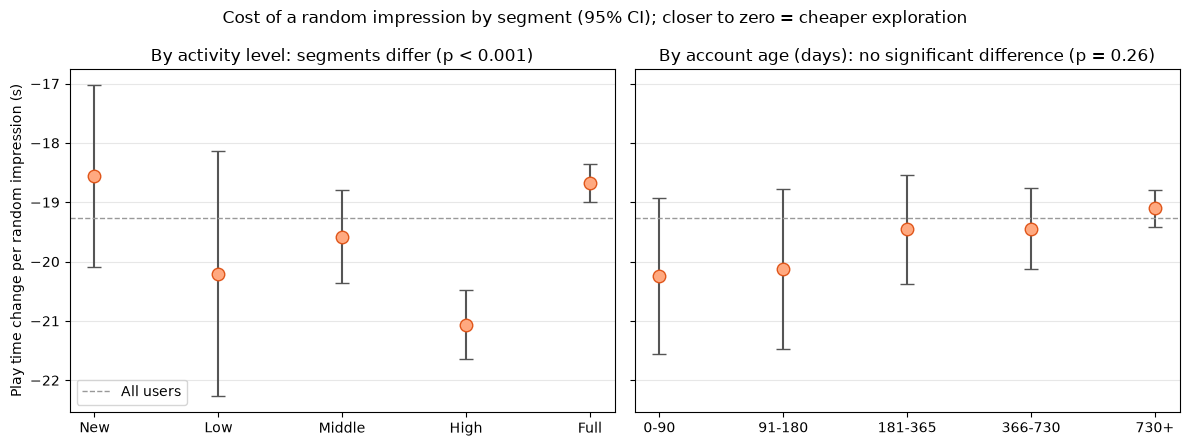

In [34]:
import matplotlib.pyplot as plt
import os

overall = -19.26   # within-user play-time effect from 01_treatment_effect

titles = {'active_group': 'By activity level', 'tenure_group': 'By account age (days)'}
labels = {'1_new': 'New', '2_low': 'Low', '3_middle': 'Middle', '4_high': 'High', '5_full': 'Full'}


def describe_p(p):
    # turn the joint-test p-value into a plain-language verdict
    p_text = 'p < 0.001' if p < 0.001 else f'p = {p:.2f}'
    verdict = 'segments differ' if p < 0.05 else 'no significant difference'
    return f'{verdict} ({p_text})'


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, seg in zip(axes, ['active_group', 'tenure_group']):
    out, p = segment_effects(df, 'play_sec', seg)
    x = [labels.get(lvl, lvl) for lvl in out.index]    # tenure ranges have no mapping and stay as they are
    ax.errorbar(x, out['est'], yerr=1.96 * out['se'], fmt='o', markersize=9, capsize=5,
                markerfacecolor='#FFA980', markeredgecolor='#E0561A', ecolor='#555555')
    ax.axhline(overall, color='#999999', linestyle='--', linewidth=1, label='All users')
    ax.set_title(f'{titles[seg]}: {describe_p(p)}')
    ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('Play time change per random impression (s)')
axes[0].legend(loc='lower left')
fig.suptitle('Cost of a random impression by segment (95% CI); closer to zero = cheaper exploration')
plt.tight_layout()
os.makedirs('../figures', exist_ok=True)
plt.savefig('../figures/hte_play_time_lift.png', dpi=150, bbox_inches='tight')
plt.show()

**Key findings:**
- **Relative cost is nearly uniform.** A random impression lowers long view and play time by roughly 74–81% in every activity and tenure group, with overlapping confidence intervals.
- **Absolute cost scales with baseline engagement.** Effects differ significantly in absolute terms (long view by activity p = 1.4e-63; play time by activity p = 9.1e-11), driven by differences in control means: segments that engage more with recommendations lose more when shown a random video.
- **Cheapest place for exploration:** full-active users (−18.7s play time per random impression) and new users (−18.6s), vs. −21.1s for high-active users. Shifting one exploration impression from high- to full-active users saves about 2.4s (≈11% of the cost). Full-active users also hold 66% of users, so they can absorb most exploration traffic.
- **Account age matters little.** Play-time cost does not differ by tenure (p = 0.26). New accounts (0–90 days) show the same ~79% relative loss as 2+-year accounts, so there is no clear evidence that random content is less costly during cold start.
- **Hate-rate heterogeneity is not robust.** Joint tests give p = 0.06 (activity) and p = 0.037 (tenure), neither below the Bonferroni threshold for six tests (≈0.008).
- Segment differences are descriptive: segments are not randomized, but the effect within each segment is causal because treatment is randomized at the impression level.